In [2]:
from pathlib import Path
import pandas as pd

# Locate CSV files inside the dataset folder
csv_files = list(Path("dataset").glob("*.csv"))

if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV file in dataset/. Found: "
        f"{[file.name for file in csv_files]}"
    )

dataset_path = csv_files[0]

# Read only five rows for initial verification
df_preview = pd.read_csv(dataset_path, nrows=5)

print("Dataset filename:", dataset_path.name)
print("Number of columns:", len(df_preview.columns))
print("Column names:", df_preview.columns.tolist())

display(df_preview)

Dataset filename: new_file.csv
Number of columns: 10
Column names: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud']


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0


In [3]:
expected_columns = [
    "step",
    "type",
    "amount",
    "nameOrig",
    "oldbalanceOrg",
    "newbalanceOrig",
    "nameDest",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud"
]

missing_columns = set(expected_columns) - set(df_preview.columns)

if not missing_columns:
    print("Dataset verification successful!")
    print("All 10 expected columns are present.")
else:
    print("Missing columns:", missing_columns)

Dataset verification successful!
All 10 expected columns are present.


In [6]:
"""
Project: Online Payment Fraud Detection using Machine Learning

Purpose:
This cell imports the Python libraries required for data analysis,
visualization, preprocessing, model training, and model evaluation.

Libraries Used:
- NumPy and Pandas: Numerical operations and dataset manipulation.
- Matplotlib and Seaborn: Data visualization and exploratory analysis.
- Scikit-learn: Data splitting, preprocessing, machine learning models,
  and evaluation metrics.
- XGBoost: Gradient-boosting classification for fraud detection.
- Path and display: File path handling and formatted notebook output.

Configuration:
- Warnings are filtered to keep notebook output readable.
- Seaborn is configured for consistent and clear visualizations.
- A fixed random state is defined for reproducible experiments.
"""

# Import utilities for locating files and displaying results in Jupyter Notebook
from pathlib import Path
from IPython.display import display
import warnings

# Import libraries for numerical calculations and dataset manipulation
import numpy as np
import pandas as pd

# Import visualization libraries for charts, graphs, and statistical analysis
import matplotlib.pyplot as plt
import seaborn as sns

# Import the function used to split data into training and testing sets
from sklearn.model_selection import train_test_split

# Import tools for combining preprocessing steps and machine learning models
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Import Logistic Regression and Random Forest classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import metrics to evaluate model performance and fraud detection results
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Import XGBoost, a gradient-boosting algorithm used for classification
from xgboost import XGBClassifier

# Suppress FutureWarning messages to keep notebook output clean
warnings.filterwarnings("ignore", category=FutureWarning)

# Set a consistent visual style for all Seaborn plots
sns.set_theme(style="whitegrid")

# Define a fixed random seed to make random operations reproducible
RANDOM_STATE = 42

# Confirm that all required libraries have been imported
print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
"""
Section: Load the Dataset

Purpose:
Locate the project's dataset directory, identify the CSV file, load the
transaction data into a Pandas DataFrame, and display an initial preview.

How it works:
- Identifies the current working directory.
- Checks whether the dataset folder exists in the current directory or
  its parent directory.
- Ensures that exactly one CSV file is available in the dataset folder.
- Loads the CSV file into a DataFrame using Pandas.
- Displays the dataset path, dimensions, and first five rows.

Expected location:
project_root/dataset/your_dataset.csv
"""

# Get the current working directory, normally the project root
project_root = Path.cwd()

# If the dataset folder is not here, check whether it exists one level above
if not (project_root / "dataset").exists() and (project_root.parent / "dataset").exists():
    project_root = project_root.parent

# Construct the path to the dataset directory
dataset_dir = project_root / "dataset"

# Find all CSV files in the dataset directory and sort their paths alphabetically
# Return an empty list if the dataset directory does not exist
csv_files = sorted(dataset_dir.glob("*.csv")) if dataset_dir.exists() else []

# Ensure exactly one CSV file is available to avoid loading the wrong dataset
if len(csv_files) != 1:
    raise FileNotFoundError(
        f"Expected exactly one CSV file in {dataset_dir}. Found: {[p.name for p in csv_files]}. "
        "Place your dataset there, or set DATASET_PATH manually."
    )

# Store the path of the identified CSV file for use in later cells
DATASET_PATH = csv_files[0]
print("Dataset path:", DATASET_PATH)

# Load the CSV data into a Pandas DataFrame
# low_memory=False helps Pandas infer column data types using the full file
data = pd.read_csv(DATASET_PATH, low_memory=False)

# Display the number of transaction records and columns in the dataset
print(f"Loaded dataset with {data.shape[0]:,} rows and {data.shape[1]} columns.")

# Display the first five rows to verify that the dataset loaded correctly
display(data.head())

Dataset path: D:\College\Projects\online-payment-fraud-detection\dataset\new_file.csv
Loaded dataset with 6,362,620 rows and 10 columns.


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0


In [8]:
"""
Section: Data Understanding and Dataset Inspection

Purpose:
Understand the structure, quality, and characteristics of the transaction
dataset before performing exploratory data analysis and model training.

This section examines:
- Dataset dimensions and column names.
- Data types and memory usage.
- Statistical summaries of numerical features.
- Missing values and duplicate records.
- Distribution of transaction types.
- Distribution of legitimate and fraudulent transactions.

Why it matters:
Understanding the dataset helps identify data quality issues, recognize
important patterns, and determine the preprocessing required before
training machine learning models.
"""

# Display the total number of rows and columns in the dataset
print("Dataset shape:", data.shape)

# Display all column names to verify the available features and target
print("\nColumn names:")
print(data.columns.tolist())

# Display column data types and the DataFrame's approximate memory usage
# deep=True analysis is requested through memory_usage="deep"
print("\nData types and memory usage:")
data.info(memory_usage="deep")

# Generate descriptive statistics for numerical columns
# Transpose the result so that each feature appears in a separate row
display(data.describe().T)

# Count missing values in each column and show columns with the most missing values first
print("\nMissing values per column:")
display(data.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

# Count completely duplicated rows to identify potentially repeated records
print("\nDuplicate rows:", f"{data.duplicated().sum():,}")

# Count transactions belonging to each payment type, such as TRANSFER and CASH_OUT
print("\nTransaction type counts:")
display(data["type"].value_counts().to_frame("count"))

# Count legitimate and fraudulent transactions, ensuring both labels are displayed
fraud_counts = data["isFraud"].value_counts().reindex([0, 1], fill_value=0)

# Calculate the percentage of each class relative to the total transaction count
fraud_percent = fraud_counts / fraud_counts.sum() * 100

# Combine the class counts and percentages into a single summary table
fraud_summary = pd.DataFrame({
    "count": fraud_counts,
    "percentage": fraud_percent.round(4)
})

# Display the target distribution: 0 represents legitimate transactions and 1 represents fraud
print("\nTarget distribution (0 = legitimate, 1 = fraud):")
display(fraud_summary)

Dataset shape: (6362620, 10)

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud']

Data types and memory usage:
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 10 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
dtypes: float64(5), int64(2), str(3)
memory usage: 1.5 GB


,count,mean,std,min,25%,50%,75%,max
step,6362620.0,2.433972e+02,1.423320e+02,1.0,156.00,239.000,3.350000e+02,7.430000e+02
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.57,74871.940,2.087215e+05,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.00,14208.000,1.073152e+05,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.00,0.000,1.442584e+05,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.00,132705.665,9.430367e+05,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.00,214661.440,1.111909e+06,3.561793e+08
isFraud,6362620.0,1.290820e-03,3.590480e-02,0.0,0.00,0.000,0.000000e+00,1.000000e+00



Missing values per column:


,missing_values
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0



Duplicate rows: 0

Transaction type counts:


,count
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432



Target distribution (0 = legitimate, 1 = fraud):


,count,percentage
isFraud,,
0,6354407,99.8709
1,8213,0.1291


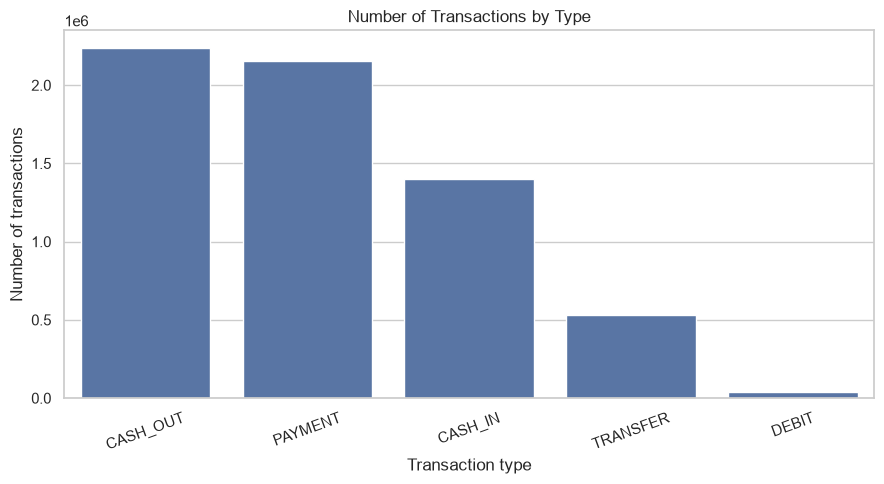

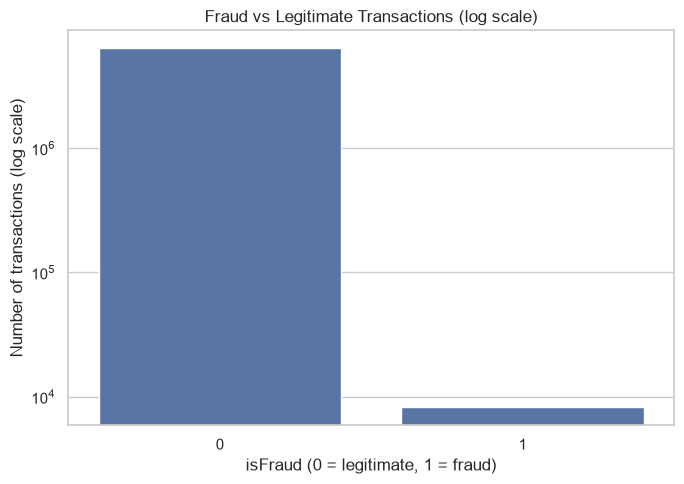

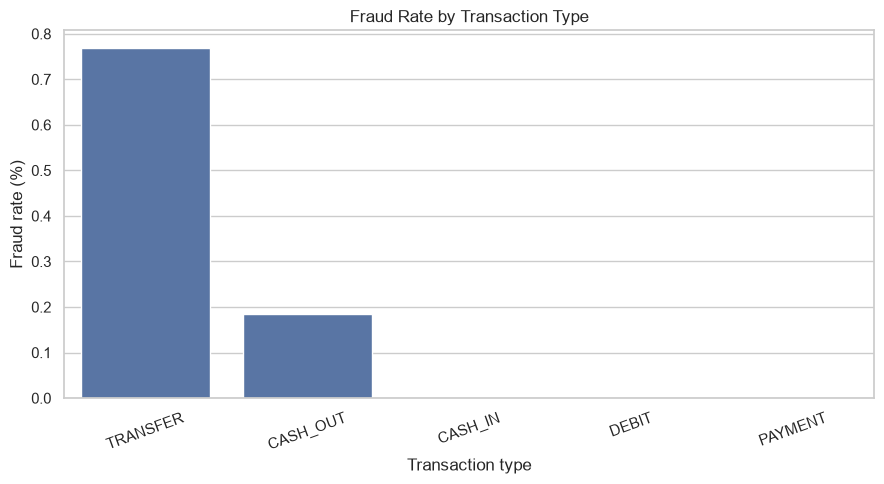

,fraud_rate_percent
type,
TRANSFER,0.768799
CASH_OUT,0.183955
CASH_IN,0.000000
DEBIT,0.000000
PAYMENT,0.000000


In [11]:
"""
Section: Exploratory Data Analysis (EDA)

Purpose:
Explore transaction patterns and investigate the relationship between
transaction types and fraudulent activities using visualizations.

This section includes:
- Transaction counts for each payment type.
- Comparison of legitimate and fraudulent transaction counts.
- Fraud percentage within each transaction type.

Why it matters:
EDA helps us understand the distribution of transactions, identify
transaction types associated with higher fraud rates, and recognize
class imbalance before training machine learning models.

Note:
The logarithmic scale is used for transaction counts because legitimate
transactions greatly outnumber fraudulent transactions.
"""

# Count the number of transactions belonging to each payment type
type_counts = data["type"].value_counts()

# Create a figure to visualize the transaction counts by type
plt.figure(figsize=(9, 5))

# Plot the number of transactions for each payment type
sns.barplot(x=type_counts.index, y=type_counts.values)

# Add a title and axis labels to make the chart easy to understand
plt.title("Number of Transactions by Type")
plt.xlabel("Transaction type")
plt.ylabel("Number of transactions")

# Rotate category labels slightly to improve readability
plt.xticks(rotation=20)

# Adjust spacing to prevent chart labels from being cut off
plt.tight_layout()

# Display the transaction count chart
plt.show()


# Count legitimate and fraudulent transactions, ensuring both labels are present
fraud_counts = data["isFraud"].value_counts().reindex([0, 1], fill_value=0)

# Create a figure to compare legitimate and fraudulent transaction counts
plt.figure(figsize=(7, 5))

# Plot the counts using string labels for the target classes
sns.barplot(x=fraud_counts.index.astype(str), y=fraud_counts.values)

# Use a logarithmic scale so the much smaller fraud count remains visible
plt.yscale("log")

# Add a title and axis labels explaining the target classes
plt.title("Fraud vs Legitimate Transactions (log scale)")
plt.xlabel("isFraud (0 = legitimate, 1 = fraud)")
plt.ylabel("Number of transactions (log scale)")

# Adjust the chart layout and display the comparison
plt.tight_layout()
plt.show()


# Calculate the percentage of fraudulent transactions within each transaction type
# Since isFraud contains 0 and 1, its mean gives the proportion of fraud cases
fraud_rate_by_type = (
    data.groupby("type")["isFraud"].mean() * 100
).sort_values(ascending=False)

# Create a figure to compare fraud rates across transaction types
plt.figure(figsize=(9, 5))

# Plot fraud percentages, with the highest fraud rate appearing first
sns.barplot(x=fraud_rate_by_type.index, y=fraud_rate_by_type.values)

# Add a title and axis labels to explain the fraud rate chart
plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction type")
plt.ylabel("Fraud rate (%)")

# Rotate category labels slightly to improve readability
plt.xticks(rotation=20)

# Adjust spacing and display the fraud rate chart
plt.tight_layout()
plt.show()

# Display the exact fraud percentage for each transaction type
display(
    fraud_rate_by_type.rename("fraud_rate_percent").to_frame()
)

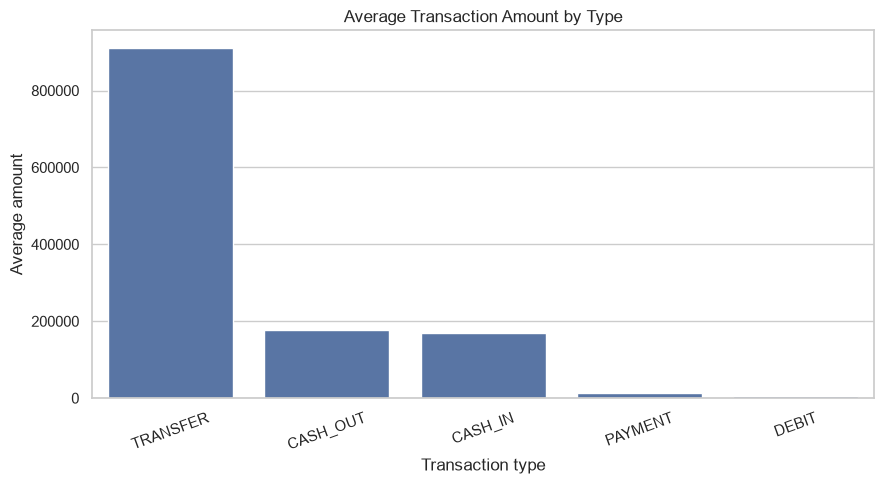

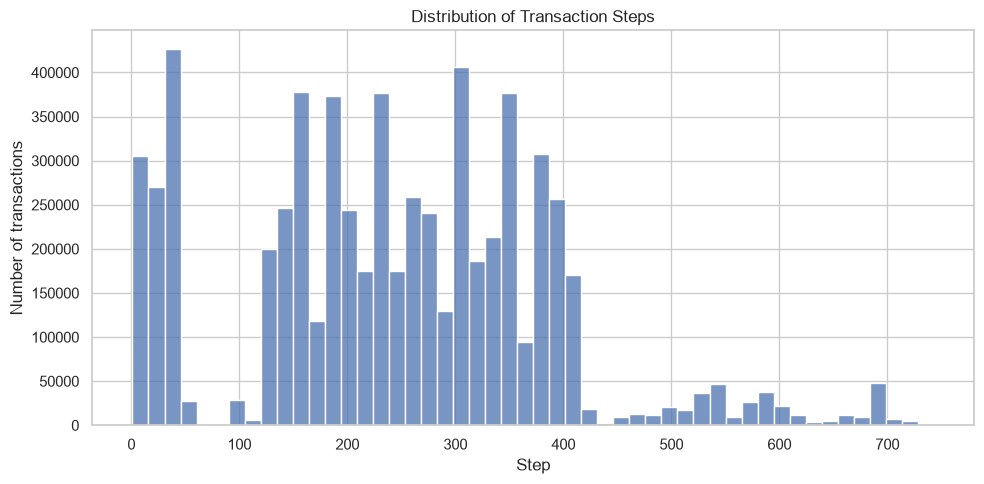

In [10]:
"""
Section: Transaction Amount and Time Analysis

Purpose:
Analyze transaction amounts across different payment types and examine
how transactions are distributed across simulation time steps.

This section includes:
- Average transaction amount for each transaction type.
- Distribution of transactions across simulation steps.

Why it matters:
Transaction amounts can vary significantly between payment types.
Analyzing simulation steps helps identify periods with higher or lower
transaction activity and provides additional context for fraud analysis.

Note:
The average transaction amount can be affected by unusually large
transactions, so it should be interpreted alongside other statistics.
"""

# Calculate the average transaction amount for each type and sort from highest to lowest
mean_amount_by_type = (
    data.groupby("type")["amount"]
    .mean()
    .sort_values(ascending=False)
)

# Create a figure for comparing average transaction amounts
plt.figure(figsize=(9, 5))

# Plot the average transaction amount for each payment type
sns.barplot(x=mean_amount_by_type.index, y=mean_amount_by_type.values)

# Add a descriptive title and labels to the chart
plt.title("Average Transaction Amount by Type")
plt.xlabel("Transaction type")
plt.ylabel("Average amount")

# Rotate the category labels slightly to improve readability
plt.xticks(rotation=20)

# Adjust spacing so the chart labels are not cut off
plt.tight_layout()

# Display the average transaction amount chart
plt.show()


# Create a figure to examine transaction activity across simulation steps
plt.figure(figsize=(10, 5))

# Plot the number of transactions falling within each of 50 step intervals
sns.histplot(data=data, x="step", bins=50)

# Add a descriptive title and labels to the histogram
plt.title("Distribution of Transaction Steps")
plt.xlabel("Step")
plt.ylabel("Number of transactions")

# Adjust the layout to prevent labels from being cut off
plt.tight_layout()

# Display the transaction step distribution
plt.show()

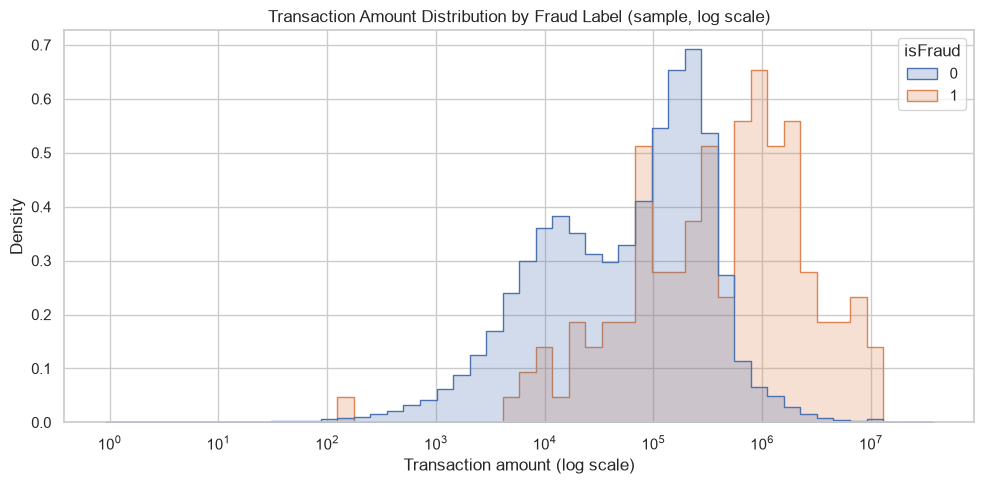

In [12]:
"""
Section: Transaction Amount Distribution by Fraud Label

Purpose:
Compare the distribution of transaction amounts for legitimate and
fraudulent transactions using a sample of the dataset.

This section:
- Selects a reproducible random sample of up to 100,000 transactions.
- Excludes non-positive amounts from this logarithmic visualization.
- Plots transaction amount distributions separately for each fraud label.
- Uses density normalization to compare distribution shapes.

Why it matters:
Fraudulent and legitimate transactions may have different amount patterns.
A logarithmic scale helps visualize amounts that vary across a wide range.

Note:
The sample is used to make plotting faster. Excluding non-positive amounts
affects only this visualization; it does not remove records from the
original dataset.
"""

# Select up to 100,000 transactions randomly to make visualization faster
# RANDOM_STATE ensures that the same sample can be reproduced
plot_sample = data.sample(
    n=min(100_000, len(data)),
    random_state=RANDOM_STATE
)

# Keep only positive transaction amounts because a logarithmic scale
# cannot display zero or negative values
positive_amount_sample = plot_sample.loc[
    plot_sample["amount"] > 0
].copy()

# Create a figure for comparing transaction amount distributions
plt.figure(figsize=(10, 5))

# Plot the amount distributions for legitimate and fraudulent transactions
sns.histplot(
    data=positive_amount_sample,
    x="amount",
    hue="isFraud",       # Separate distributions using the fraud target label
    bins=50,              # Divide the amount range into 50 intervals
    log_scale=True,       # Use a logarithmic scale for transaction amounts
    stat="density",       # Show probability density instead of raw counts
    common_norm=False,    # Normalize each fraud class independently
    element="step",       # Use step outlines to make distributions easier to compare
)

# Add a descriptive title and axis labels
plt.title("Transaction Amount Distribution by Fraud Label (sample, log scale)")
plt.xlabel("Transaction amount (log scale)")
plt.ylabel("Density")

# Adjust spacing to prevent labels from being cut off
plt.tight_layout()

# Display the transaction amount distribution chart
plt.show()

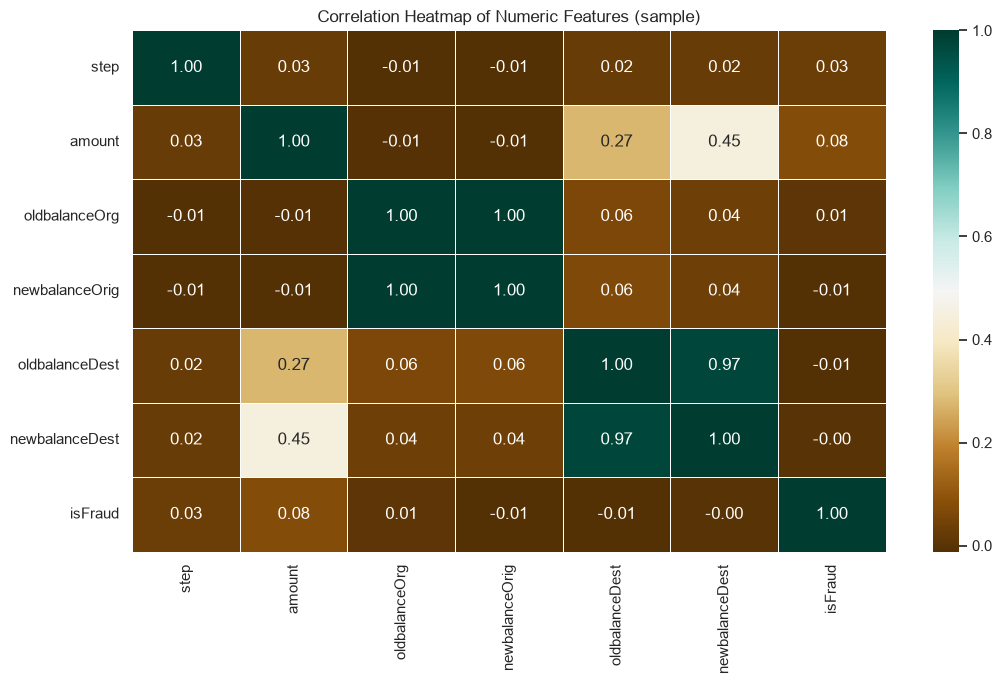

In [13]:
"""
Section: Correlation Analysis of Numerical Features

Purpose:
Examine the linear relationships between numerical transaction features
and the fraud target using a correlation matrix and heatmap.

This section:
- Selects relevant numerical columns from the dataset.
- Checks whether all expected columns are available.
- Uses a reproducible random sample to reduce computation time.
- Calculates Pearson correlation coefficients.
- Visualizes the results using a heatmap.

Why it matters:
Correlation analysis helps identify numerical features that move together
and provides an initial view of their linear relationships with the
fraud label. These insights can guide further feature analysis.

Note:
Correlation does not establish causation, and a weak linear correlation
does not necessarily mean a feature is unimportant to a machine learning model.
"""

# Define the numerical features and target column to include in the analysis
numeric_columns = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud"
]

# Identify any required columns that are missing from the dataset
missing_numeric_columns = [
    col for col in numeric_columns if col not in data.columns
]

# Stop execution with a clear error message if expected columns are unavailable
if missing_numeric_columns:
    raise ValueError(
        f"Expected numeric columns are missing: {missing_numeric_columns}"
    )

# Select a reproducible sample of up to 100,000 rows to reduce computation time
corr_sample = data[numeric_columns].sample(
    n=min(100_000, len(data)),
    random_state=RANDOM_STATE
)

# Calculate Pearson correlation coefficients between the selected columns
corr = corr_sample.corr(numeric_only=True)

# Create a figure for displaying the correlation matrix
plt.figure(figsize=(11, 7))

# Visualize the correlation coefficients using a heatmap
# Annotations show the coefficients to two decimal places
sns.heatmap(
    corr,
    cmap="BrBG",
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

# Add a descriptive title to the heatmap
plt.title("Correlation Heatmap of Numeric Features (sample)")

# Adjust spacing so the title and labels are displayed correctly
plt.tight_layout()

# Display the correlation heatmap
plt.show()

In [14]:
"""
Section: Data Preprocessing and Feature Preparation

Purpose:
Validate the dataset, prepare the records for machine learning, and
separate the input features from the target variable.

This section:
- Verifies that all required dataset columns are available.
- Checks that the target column contains valid fraud labels.
- Selects a manageable, stratified sample for model training when needed.
- Excludes account identifiers from the predictor features.
- Separates the input features (X) and target variable (y).
- Converts the categorical transaction type into numerical indicator columns.

Why it matters:
Machine learning algorithms require appropriately formatted input features
and a clearly defined target variable. These steps prepare the dataset
for splitting, model training, and evaluation.

Note:
The original dataset remains unchanged. Sampling and transformations are
applied to a separate DataFrame used for model development.
"""

# Define the columns required for preprocessing and model development
required_columns = [
    "step", "type", "amount", "nameOrig", "oldbalanceOrg", "newbalanceOrig",
    "nameDest", "oldbalanceDest", "newbalanceDest", "isFraud"
]

# Identify required columns that are missing from the dataset
missing_columns = [
    col for col in required_columns if col not in data.columns
]

# Stop execution if the dataset does not contain all required columns
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Check that the target variable does not contain missing values
if data["isFraud"].isna().any():
    raise ValueError("The isFraud target column contains missing values.")

# Ensure that the target variable contains only valid binary labels: 0 and 1
if not set(data["isFraud"].unique()).issubset({0, 1}):
    raise ValueError("Expected isFraud to contain only 0 and 1.")

# Set the maximum number of rows to use for model development
# Set to None if you want to use the entire dataset
MAX_MODEL_ROWS = 500_000

# If the dataset exceeds the limit, select a stratified sample of transactions
if MAX_MODEL_ROWS is not None and len(data) > MAX_MODEL_ROWS:

    # Preserve approximately the same fraud-to-legitimate ratio in the sample
    # A fixed random state makes the sampling reproducible
    sampled_indices, _ = train_test_split(
        data.index,
        train_size=MAX_MODEL_ROWS,
        random_state=RANDOM_STATE,
        stratify=data["isFraud"],
    )

    # Create a separate DataFrame containing only the selected records and columns
    model_data = data.loc[sampled_indices, required_columns].copy()

    print(f"Using a stratified sample of {len(model_data):,} rows for model training.")

else:
    # Use all available records when the dataset is within the configured limit
    model_data = data.loc[:, required_columns].copy()

    print(f"Using all {len(model_data):,} rows for model training.")

# Separate the predictor features from the fraud target
# Exclude sender and receiver identifiers to avoid using account IDs as predictors
X = model_data.drop(columns=["isFraud", "nameOrig", "nameDest"])

# Store the target labels as integers: 0 = legitimate and 1 = fraudulent
y = model_data["isFraud"].astype(int)

# Convert the categorical transaction type into numerical indicator columns
# drop_first=True removes one category to avoid redundant dummy variables
# dtype=np.int8 stores the binary indicator columns using less memory
X = pd.get_dummies(
    X,
    columns=["type"],
    drop_first=True,
    dtype=np.int8
)

# Display the number of records and predictor features after preprocessing
print("Feature matrix shape:", X.shape)

# Display the number of target labels
print("Target shape:", y.shape)

# Count the fraudulent transactions available for model development
print("Fraud cases in model data:", int((y == 1).sum()))

# Preview the prepared feature matrix
display(X.head())

Using a stratified sample of 500,000 rows for model training.
Feature matrix shape: (500000, 10)
Target shape: (500000,)
Fraud cases in model data: 645


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
5763161,400,1355885.08,11398.0,0.00,259752.71,1615637.79,0,0,0,1
1309655,136,9677.08,5169.0,0.00,0.00,9677.08,1,0,0,0
5031478,354,107735.09,49783.0,157518.09,1010420.41,902685.32,0,0,0,0
3131324,236,13095.33,20141.0,7045.67,0.00,0.00,0,0,1,0
4617576,329,106739.61,143144.0,36404.39,6205474.27,6312213.88,1,0,0,0


In [15]:
"""
Section: Splitting Data into Training and Testing Sets

Purpose:
Divide the prepared dataset into separate training and testing sets
so that machine learning models can be trained and evaluated fairly.

This section:
- Uses 70% of the data for training and 30% for testing.
- Sets a fixed random state for reproducibility.
- Uses stratified splitting to preserve the fraud-to-legitimate ratio.
- Displays the sizes of both sets and their fraud case counts.

Why it matters:
The training set is used to teach the model to recognize transaction
patterns, while the testing set evaluates how well the trained model
performs on data that was not used during training.
"""

# Split the feature matrix and target variable into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,                      # Input features used by the machine learning models
    y,                      # Target labels: 0 = legitimate, 1 = fraud
    test_size=0.30,          # Allocate 30% of the data to testing
    random_state=RANDOM_STATE,  # Make the split reproducible
    stratify=y,              # Preserve the approximate class proportions in both sets
)

# Display the dimensions of the training feature matrix
print("Training features:", X_train.shape)

# Display the dimensions of the testing feature matrix
print("Testing features:", X_test.shape)

# Count fraudulent transactions in the training target
print("Fraud cases in training set:", int((y_train == 1).sum()))

# Count fraudulent transactions in the testing target
print("Fraud cases in testing set:", int((y_test == 1).sum()))

Training features: (350000, 10)
Testing features: (150000, 10)
Fraud cases in training set: 451
Fraud cases in testing set: 194


In [16]:
"""
Section: Model Training and Initial Evaluation

Purpose:
Train three machine learning classifiers to distinguish fraudulent
transactions from legitimate transactions and compare their performance.

Models Used:
1. Logistic Regression: A linear classification model used as a baseline.
2. Random Forest: An ensemble of decision trees that captures nonlinear patterns.
3. XGBoost: A gradient-boosting model designed to learn complex relationships.

This section:
- Calculates the imbalance ratio between legitimate and fraudulent transactions.
- Configures class imbalance handling for the three models.
- Trains each model using the training dataset.
- Generates fraud probabilities and binary predictions on the test dataset.
- Calculates ROC-AUC, average precision, precision, recall, and F1-score.
- Stores the trained models and predictions for later analysis.

Why it matters:
Comparing different classifiers helps us understand which approaches
identify fraudulent transactions effectively. Multiple evaluation metrics
are necessary because accuracy alone can be misleading when fraud cases
are rare.

Important:
The current implementation evaluates every model on the test set.
For a more rigorous final evaluation, use a separate validation set or
cross-validation for model selection, then evaluate the chosen model
once on an untouched test set.
"""

# Count legitimate transactions (class 0) in the training dataset
negative_count = int((y_train == 0).sum())

# Count fraudulent transactions (class 1) in the training dataset
positive_count = int((y_train == 1).sum())

# Stop execution if the training dataset contains no fraudulent transactions
if positive_count == 0:
    raise ValueError(
        "No fraud cases in training data. Increase MAX_MODEL_ROWS or check the dataset."
    )

# Calculate the legitimate-to-fraud ratio for XGBoost class weighting
# A larger value gives greater weight to fraudulent transactions during training
scale_pos_weight = negative_count / positive_count
print(f"XGBoost scale_pos_weight: {scale_pos_weight:.2f}")


# Define the machine learning models and their configurations
models = {

    # Standardize the features before fitting Logistic Regression
    # Balanced class weights help compensate for the unequal class distribution
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=500,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    ),

    # Train an ensemble of decision trees using Random Forest
    # Balanced subsampling adjusts class weights within individual tree samples
    "Random Forest": RandomForestClassifier(
        n_estimators=50,             # Number of trees in the forest
        criterion="entropy",         # Criterion used to measure split quality
        class_weight="balanced_subsample",
        min_samples_leaf=2,           # Minimum number of samples required at a leaf
        n_jobs=-1,                    # Use available CPU cores
        random_state=RANDOM_STATE,    # Make training more reproducible
    ),

    # Configure XGBoost to learn patterns through sequential boosting
    # scale_pos_weight compensates for the imbalance between legitimate and fraud cases
    "XGBoost": XGBClassifier(
        n_estimators=150,             # Number of boosting rounds
        max_depth=6,                  # Maximum depth of each tree
        learning_rate=0.1,            # Contribution of each boosting round
        subsample=0.8,                # Fraction of training samples used per tree
        colsample_bytree=0.8,         # Fraction of features considered per tree
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",        # Evaluation metric used by XGBoost during training
        tree_method="hist",           # Efficient histogram-based tree construction
        n_jobs=-1,                    # Use available CPU cores
        random_state=RANDOM_STATE,
    ),
}


# Create dictionaries and a list to store trained models, predictions, and results
trained_models = {}
prediction_cache = {}
results = []

# Train and evaluate each configured model in sequence
for model_name, model in models.items():

    # Display the name of the model currently being trained
    print(f"Training {model_name}...")

    # Fit the model using only the training features and their corresponding labels
    model.fit(X_train, y_train)

    # Predict the probability that each test transaction is fraudulent
    # Column 1 contains the probability of class 1 (fraud)
    probabilities = model.predict_proba(X_test)[:, 1]

    # Convert probabilities into binary predictions using a threshold of 0.5
    # Probabilities >= 0.5 are classified as fraud; the rest as legitimate
    predictions = (probabilities >= 0.5).astype(int)

    # Calculate evaluation metrics from the actual labels and predicted probabilities
    # ROC-AUC measures how well the model ranks fraudulent transactions above legitimate ones
    # Average precision summarizes precision-recall performance across probability thresholds
    # Precision measures how many flagged transactions are actually fraudulent
    # Recall measures how many actual fraudulent transactions are detected
    # F1-score balances precision and recall
    results.append({
        "Model": model_name,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC (Average Precision)": average_precision_score(y_test, probabilities),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
    })

    # Save the fitted model so it can be inspected and reused later
    trained_models[model_name] = model

    # Cache probabilities and binary predictions for later comparison and visualization
    prediction_cache[model_name] = {
        "probabilities": probabilities,
        "predictions": predictions,
    }

    # Confirm that the current model has finished training and evaluation
    print(f"Finished {model_name}.")

# Confirm that all three models have been processed
print("All models have been trained and evaluated.")

XGBoost scale_pos_weight: 775.05
Training Logistic Regression...
Finished Logistic Regression.
Training Random Forest...
Finished Random Forest.
Training XGBoost...
Finished XGBoost.
All models have been trained and evaluated.


,Model,ROC-AUC,PR-AUC (Average Precision),Precision,Recall,F1-score
0,XGBoost,0.9995,0.9048,0.5313,0.9175,0.6730
1,Random Forest,0.9759,0.8528,0.9781,0.6907,0.8097
2,Logistic Regression,0.9888,0.5572,0.0253,0.9433,0.0492


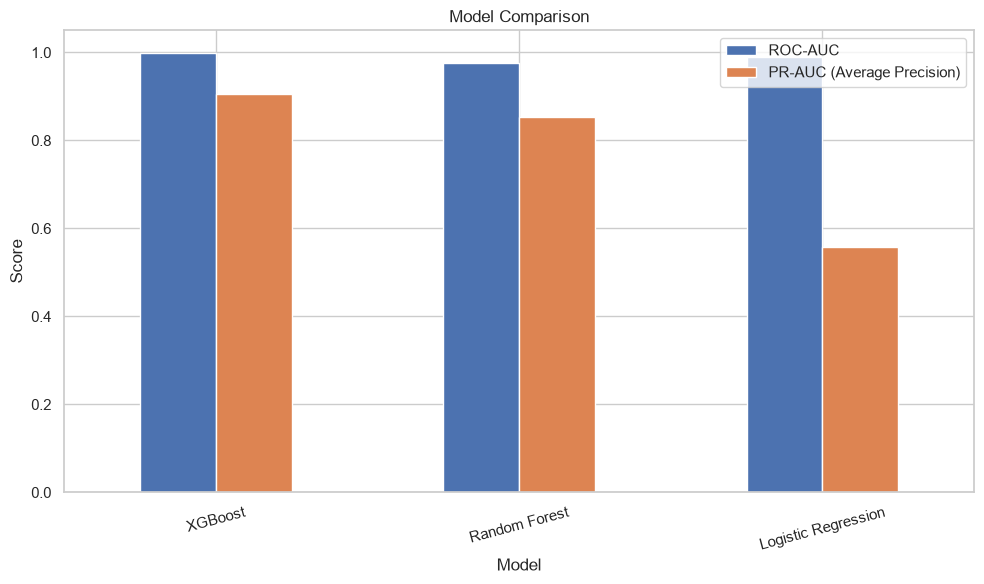

In [17]:
"""
Section: Model Comparison and Performance Visualization

Purpose:
Compare the performance of Logistic Regression, Random Forest, and
XGBoost using the evaluation metrics calculated in the previous cell.

This section:
- Converts the collected evaluation results into a Pandas DataFrame.
- Sorts the models by Average Precision.
- Formats metric values for clear presentation.
- Creates a bar chart comparing ROC-AUC and Average Precision.

Why it matters:
A comparison table makes it easier to examine multiple evaluation metrics,
while the bar chart provides a visual summary of model performance.

Note:
Average Precision summarizes precision-recall performance across
classification thresholds. It is particularly useful for imbalanced
fraud detection datasets. Model selection should also consider recall,
precision, and the operational cost of missed fraud and false alarms.
"""

# Convert the evaluation results for all trained models into a DataFrame
# Sort models by Average Precision, with the highest value appearing first
results_df = pd.DataFrame(results).sort_values(
    by="PR-AUC (Average Precision)",
    ascending=False
).reset_index(drop=True)

# Format metric values to four decimal places for easier comparison
# This affects the notebook's displayed table, not the underlying results
display(results_df.style.format({
    "ROC-AUC": "{:.4f}",
    "PR-AUC (Average Precision)": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-score": "{:.4f}",
}))

# Select ROC-AUC and Average Precision for the visual model comparison
plot_metrics = results_df.set_index("Model")[
    ["ROC-AUC", "PR-AUC (Average Precision)"]
]

# Create a grouped bar chart to compare the two ranking metrics
plot_metrics.plot(kind="bar", figsize=(10, 6))

# Add a title and label the vertical axis
plt.title("Model Comparison")
plt.ylabel("Score")

# Set the y-axis range to display scores between 0 and slightly above 1
plt.ylim(0, 1.05)

# Rotate model names slightly to improve readability
plt.xticks(rotation=15)

# Adjust spacing to prevent labels from being cut off
plt.tight_layout()

# Display the model comparison chart
plt.show()

Selected model based on test average precision: XGBoost

Classification report at threshold 0.5:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    149806
       Fraud       0.53      0.92      0.67       194

    accuracy                           1.00    150000
   macro avg       0.77      0.96      0.84    150000
weighted avg       1.00      1.00      1.00    150000



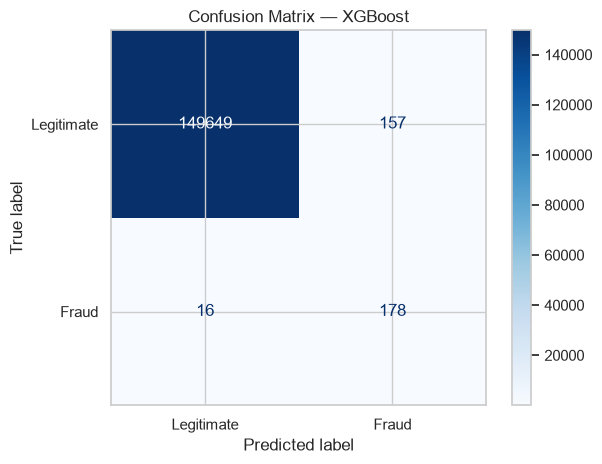

In [18]:
"""
Section: Confusion Matrix and Classification Report

Purpose:
Evaluate the selected machine learning model by comparing its predictions
with the actual transaction labels in the test dataset.

This section:
- Selects the model with the highest Average Precision from results_df.
- Retrieves its trained model, predicted labels, and fraud probabilities.
- Displays a classification report with precision, recall, and F1-score.
- Creates a confusion matrix to visualize correct and incorrect predictions.

Why it matters:
Fraud detection requires more than a single performance score. The
classification report summarizes performance for each class, while the
confusion matrix reveals how many fraudulent transactions were detected,
missed, or incorrectly flagged.

Note:
The current selection uses test-set Average Precision. For a rigorous
final evaluation, select the model using validation data and reserve the
test set for evaluating the chosen model only once.
"""

# Identify the model with the highest Average Precision in the comparison table
best_model_name = results_df.loc[0, "Model"]

# Retrieve the fitted model corresponding to the selected model name
best_model = trained_models[best_model_name]

# Retrieve the binary predictions generated using the 0.5 probability threshold
best_predictions = prediction_cache[best_model_name]["predictions"]

# Retrieve the predicted fraud probabilities for further analysis if required
best_probabilities = prediction_cache[best_model_name]["probabilities"]

# Display the name of the selected model and the selection criterion
print("Selected model based on test average precision:", best_model_name)

# Display a classification report using the actual labels and predicted labels
# Precision, recall, and F1-score are reported separately for each class
print("\nClassification report at threshold 0.5:")
print(classification_report(
    y_test,                         # Actual labels from the test dataset
    best_predictions,                # Predicted labels from the selected model
    labels=[0, 1],                   # Explicitly specify legitimate and fraud classes
    target_names=["Legitimate", "Fraud"],
    zero_division=0,                 # Return 0 when a metric has a zero denominator
))

# Generate a confusion matrix by comparing actual and predicted class labels
ConfusionMatrixDisplay.from_predictions(
    y_test,                          # Actual test labels
    best_predictions,                # Model predictions
    labels=[0, 1],                   # Keep the class order consistent
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",                    # Use a blue color scheme for the matrix
    values_format="d",               # Display cell counts as integers
)

# Add a title identifying the model represented by the confusion matrix
plt.title(f"Confusion Matrix — {best_model_name}")

# Adjust spacing so the title and matrix are displayed clearly
plt.tight_layout()

# Display the confusion matrix
plt.show()

In [19]:
best_row = results_df.iloc[0]
print("CONCLUSION")
print("----------")
print(
    f"Among the three tested classifiers, {best_row['Model']} achieved the highest "
    f"average precision (PR-AUC) of {best_row['PR-AUC (Average Precision)']:.4f} "
    f"on the held-out test set. Its ROC-AUC was {best_row['ROC-AUC']:.4f}, "
    f"precision was {best_row['Precision']:.4f}, recall was {best_row['Recall']:.4f}, "
    f"and F1-score was {best_row['F1-score']:.4f} at a threshold of 0.5."
)
print(
    "These results depend on the dataset, the selected training sample, and the "
    "model settings. Since fraudulent transactions are rare, precision and recall "
    "should be considered alongside ROC-AUC. The model and decision threshold "
    "would need further validation before any real-world use."
)

CONCLUSION
----------
Among the three tested classifiers, XGBoost achieved the highest average precision (PR-AUC) of 0.9048 on the held-out test set. Its ROC-AUC was 0.9995, precision was 0.5313, recall was 0.9175, and F1-score was 0.6730 at a threshold of 0.5.
These results depend on the dataset, the selected training sample, and the model settings. Since fraudulent transactions are rare, precision and recall should be considered alongside ROC-AUC. The model and decision threshold would need further validation before any real-world use.
